# 06. Occlusion Robustness: ResNet-50 vs ViT-B/16

## 1. Introduction
How does classification accuracy change when a square region is hidden? Compare
center and random masks at 0%, 10%, 20%, 30%, 40%, and 50% image area.

Masks use gray RGB `(128, 128, 128)` on the **224×224 image after each model's
own resize/center crop and before normalization**. Coordinates are paired by
image ID and severity across models. The different resize sizes (232 vs 256)
mean that paired coordinates need not hide exactly the same original scene content.


## 2. Setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import islice
import csv
import hashlib
import importlib.metadata
import json
import math
import random
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm
from IPython.display import display

# Cho phép mở notebook từ repository root hoặc thư mục notebooks.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.models import load_model
from src.data import load_analysis_manifest, iter_analysis_images
from src.evaluation import evaluate, accuracy_drop, save_predictions

N_IMAGES = 10000
BATCH_SIZE = 16
SEED = 42
SEVERITIES = [0, 10, 20, 30, 40, 50]  # Phần trăm diện tích, không phải độ dài cạnh.
POSITIONS = ["center", "random"]
FILL_RGB = (128, 128, 128)
MODEL_NAMES = ["resnet50", "vit_b_16"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), "CUDA GPU is required; do not run the full pilot on CPU."
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda")

# Mỗi lần chạy có thư mục riêng để không ghi đè pilot hoặc baseline cũ.
RUN_ID = f"{'pilot' if N_IMAGES < 10000 else 'full'}{N_IMAGES}_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
METRICS_DIR = ROOT / "results/metrics/experiments/occlusion" / RUN_ID / "final"
FIGURES_DIR = ROOT / "results/figures/experiments/occlusion" / RUN_ID / "final"
print("GPU:", torch.cuda.get_device_name(0))
print("Run:", RUN_ID, "| Images:", N_IMAGES, "| Batch size:", BATCH_SIZE)

GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Run: full10000_20261105T051900440637Z | Images: 10000 | Batch size: 16


## 3. Data & Models
Use the first `N_IMAGES` rows of the committed analysis manifest, never the old
5,000-image pilot. Load both models through the shared API with their fixed
weights. Only small image batches are kept in memory, including for a future
10,000-image run.

In [2]:
records = load_analysis_manifest(limit=N_IMAGES)
expected_labels = {row["image_id"]: row["label"] for row in records}
print("Selected images:", len(records), "| Classes:", len({row["label"] for row in records}))

models, transforms, model_metadata = {}, {}, {}
for name in MODEL_NAMES:
    models[name], transforms[name], model_metadata[name] = load_model(name, device=DEVICE)
    print(name, model_metadata[name]["weights"], "| resize:", transforms[name].resize_size)

Selected images: 10000 | Classes: 1000
resnet50 ResNet50_Weights.IMAGENET1K_V2 | resize: [232]
vit_b_16 ViT_B_16_Weights.IMAGENET1K_V1 | resize: [256]


## 4. Occlusion Function
The official transform is split using its own resize/crop/interpolation/antialias
and normalization attributes. At 0%, this produces exactly the official transform.

For area fraction `a`, square side length is `round(224 * sqrt(a))`. Pixel rounding
makes the realized area slightly different from the requested percentage; both
are recorded. Random positions use a stable SHA-256 seed from `(seed, image_id,
severity)`, independent of model and iteration order. The square stays inside the
image. Bounds use exclusive right/bottom coordinates.

In [3]:
def resize_crop(image, transform):
    # Giữ nguyên resize/crop của checkpoint, chưa chuyển tensor hoặc normalize.
    image = TF.resize(image, transform.resize_size,
                      interpolation=transform.interpolation, antialias=transform.antialias)
    return TF.center_crop(image, transform.crop_size)


def normalize_image(image, transform):
    # Giống ImageClassification của torchvision: uint8 -> float [0,1] -> normalize.
    tensor = TF.convert_image_dtype(TF.pil_to_tensor(image), torch.float)
    return TF.normalize(tensor, mean=transform.mean, std=transform.std)


def mask_box(image_id, severity, position):
    side = round(224 * math.sqrt(severity / 100))
    if severity == 0:
        return (0, 0, 0, 0)
    if position == "center":
        left = top = (224 - side) // 2
    else:
        # Không dùng hash() của Python vì kết quả có thể đổi giữa các phiên chạy.
        key = f"{SEED}|{image_id}|{severity}".encode("utf-8")
        rng = random.Random(int.from_bytes(hashlib.sha256(key).digest(), "big"))
        left, top = rng.randint(0, 224 - side), rng.randint(0, 224 - side)
    return (left, top, left + side, top + side)


def apply_occlusion(image, image_id, severity, position):
    # Sao chép ảnh để không sửa ảnh clean hoặc ảnh dùng cho điều kiện tiếp theo.
    masked = image.copy()
    if severity:
        masked.paste(FILL_RGB, mask_box(image_id, severity, position))
    return masked

area_table = pd.DataFrame([
    {"severity": area, "side_px": round(224 * math.sqrt(area / 100)),
     "realized_area_pct": 100 * round(224 * math.sqrt(area / 100)) ** 2 / 224 ** 2}
    for area in SEVERITIES
])
display(area_table.round(3))

,severity,side_px,realized_area_pct
0,0,0,0.000
1,10,71,10.047
2,20,100,19.930
3,30,123,30.152
4,40,142,40.187
5,50,158,49.753


## 5. Visualization Check
Review three selected images for **both models** before running the experiment.
Columns show clean, center 30%, and random 30%. Captions include image IDs.
The assertions check clean preprocessing, a no-op mask at 0%, mask coordinates,
bounds and area. No intermediate images are saved individually.

PASS: official preprocessing, clean 0%, paired mask coordinates and square areas.


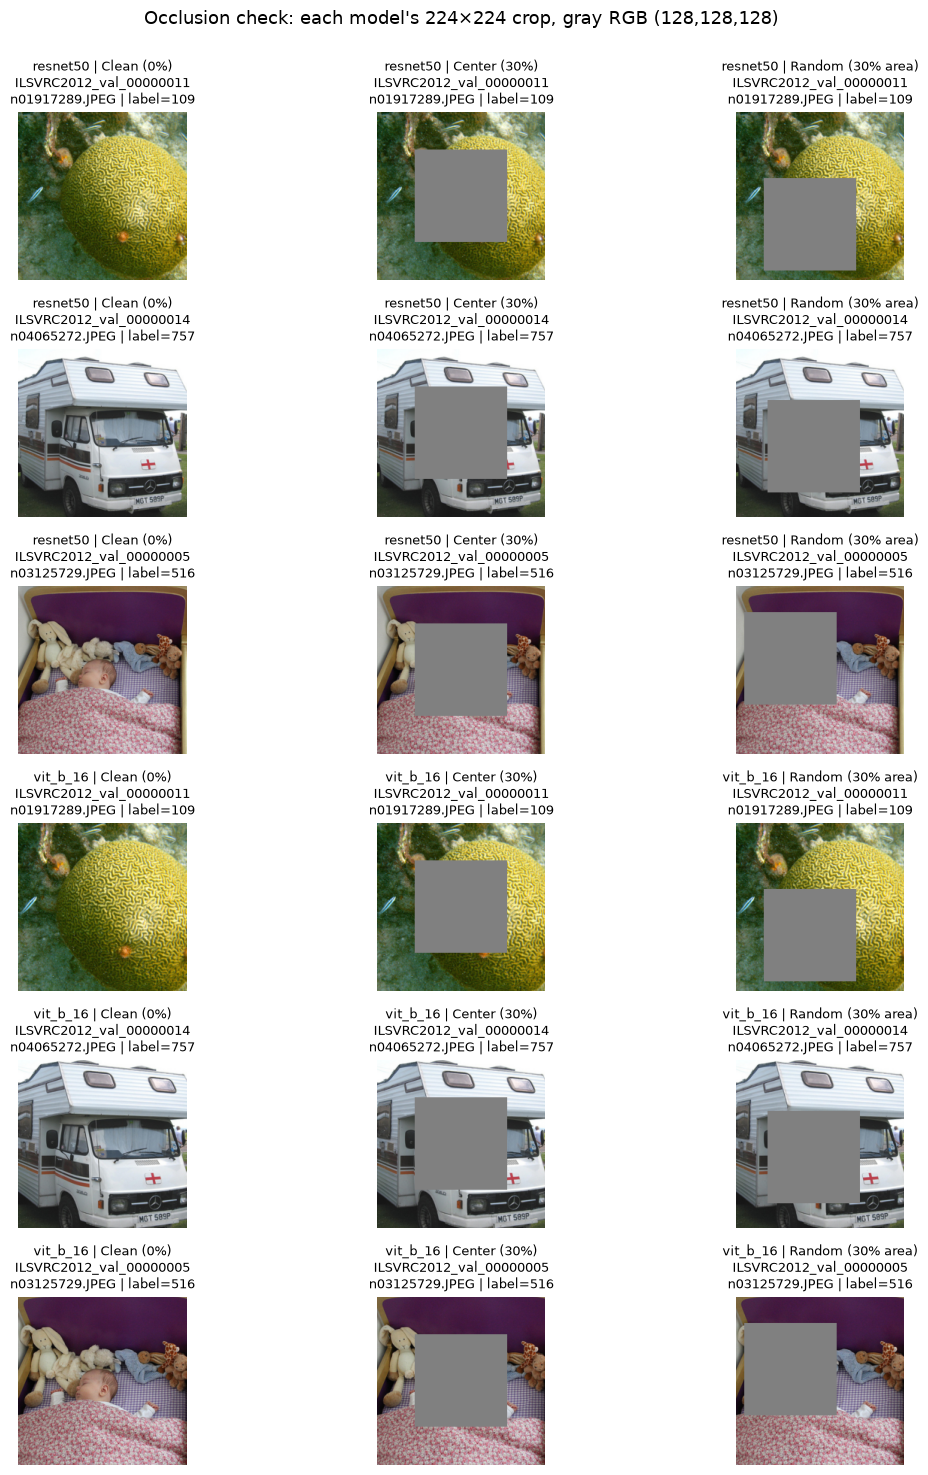

In [4]:
preview_records = records[:3]
preview = list(iter_analysis_images(preview_records))
assert {image_id: label for _, label, image_id in preview} == {
    row["image_id"]: row["label"] for row in preview_records
}
fig, axes = plt.subplots(len(preview) * len(MODEL_NAMES), 3, figsize=(12, 5 * len(preview)))
for model_index, name in enumerate(MODEL_NAMES):
    transform = transforms[name]
    for index, (image, label, image_id) in enumerate(preview):
        cropped = resize_crop(image, transform)
        assert cropped.size == (224, 224)
        assert torch.equal(normalize_image(cropped, transform), transform(image))
        for position in POSITIONS:
            assert np.array_equal(np.asarray(apply_occlusion(cropped, image_id, 0, position)), np.asarray(cropped))
            for severity in SEVERITIES[1:]:
                box = mask_box(image_id, severity, position)
                # Tọa độ chỉ phụ thuộc ID/severity/position, không phụ thuộc model.
                left, top, right, bottom = box
                assert 0 <= left < right <= 224 and 0 <= top < bottom <= 224
                assert (right - left) ** 2 == round(224 * math.sqrt(severity / 100)) ** 2
                masked = apply_occlusion(cropped, image_id, severity, position)
                assert (np.asarray(masked)[top:bottom, left:right] == np.array(FILL_RGB)).all()
        variants = [cropped, apply_occlusion(cropped, image_id, 30, "center"),
                    apply_occlusion(cropped, image_id, 30, "random")]
        row = model_index * len(preview) + index
        # Tách ID thành hai dòng để tiêu đề không đè lên ảnh bên cạnh.
        caption_id = image_id.replace("_n", "\nn")
        for column, (variant, title) in enumerate(zip(variants, ["Clean (0%)", "Center (30%)", "Random (30% area)"])):
            axes[row, column].imshow(variant)
            axes[row, column].set_title(f"{name} | {title}\n{caption_id} | label={label}", fontsize=9)
            axes[row, column].axis("off")
fig.suptitle("Occlusion check: each model's 224×224 crop, gray RGB (128,128,128)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.98))
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "occlusion_examples.png", dpi=140, bbox_inches="tight")
plt.show()
print("PASS: official preprocessing, clean 0%, paired mask coordinates and square areas.")

## 6. Experiment
Read selected images once in batches. For each model, crop each batch once,
compute clean predictions once, then evaluate the ten nonzero mask conditions.
Reuse the shared evaluation function for inference and prediction formatting.

Severity 0% is stored once with `condition="clean"` and reused in both position
curves. Each model therefore has `11 × N_IMAGES` prediction rows, not 12 repeated
conditions. This cell runs only the configured subset; it does not run the full
baseline or load all selected RGB images into RAM.

In [5]:
predictions = {name: [] for name in MODEL_NAMES}
image_stream = iter_analysis_images(records)
seen_labels = {}

with tqdm(total=N_IMAGES, desc="Occlusion images") as progress:
    while True:
        batch = list(islice(image_stream, BATCH_SIZE))
        if not batch:
            break
        seen_labels.update({image_id: label for _, label, image_id in batch})
        for name in MODEL_NAMES:
            transform = transforms[name]
            cropped_samples = [(resize_crop(image, transform), label, image_id)
                               for image, label, image_id in batch]
            # evaluate() nhận transform callable; ở đây chỉ normalize vì ảnh đã crop.
            normalize = lambda image: normalize_image(image, transform)
            rows, _ = evaluate(models[name], normalize, cropped_samples,
                               model_name=name, batch_size=BATCH_SIZE,
                               experiment="occlusion", condition="clean", severity=0)
            predictions[name].extend(rows)
            for position in POSITIONS:
                for severity in SEVERITIES[1:]:
                    masked_samples = ((apply_occlusion(image, image_id, severity, position), label, image_id)
                                      for image, label, image_id in cropped_samples)
                    rows, _ = evaluate(models[name], normalize, masked_samples,
                                       model_name=name, batch_size=BATCH_SIZE,
                                       experiment="occlusion", condition=position, severity=severity)
                    predictions[name].extend(rows)
        progress.update(len(batch))

assert seen_labels == expected_labels
assert all(len(predictions[name]) == N_IMAGES * 11 for name in MODEL_NAMES)
print("Evaluated", len(seen_labels), "unique images per condition;", N_IMAGES * 11, "prediction rows per model.")

Evaluated 10000 unique images per condition; 110000 prediction rows per model.


## 7. Metrics & Results
All comparisons join by `image_id` on the current subset. The 50,000-image
baseline accuracy is never subtracted from subset accuracy.

- `top1_accuracy`, `top5_accuracy`: accuracy in percent.
- `absolute_drop_pp`, `relative_drop_pct`: **Top-1** drop in pp and percent.
- `absolute_top5_drop_pp`, `relative_top5_drop_pct`: corresponding Top-5 drops.
- `prediction_consistency`: percent with the same Top-1 class as clean, whether
  correct or incorrect. It is not accuracy.

Drops may be negative if accuracy improves. Relative drop is undefined when
clean accuracy is zero. Predictions use the shared schema; masks and cohort are
recorded for reproducibility, without saving tensors or intermediate images.

In [6]:
metric_rows = []
for name in MODEL_NAMES:
    clean_rows = [row for row in predictions[name] if row["severity"] == 0]
    clean_by_id = {row["image_id"]: row for row in clean_rows}
    assert len(clean_by_id) == N_IMAGES
    for position in POSITIONS:
        for severity in SEVERITIES:
            current = clean_rows if severity == 0 else [
                row for row in predictions[name]
                if row["condition"] == position and row["severity"] == severity
            ]
            assert len(current) == N_IMAGES and {row["image_id"] for row in current} == set(expected_labels)
            drops = accuracy_drop(clean_rows, current, model_name=name)
            consistency = 100 * sum(row["pred_top1"] == clean_by_id[row["image_id"]]["pred_top1"]
                                    for row in current) / N_IMAGES
            metric_rows.append({
                "model_name": name, "position": position, "severity": severity,
                "n_images": drops["num_images"],
                "top1_accuracy": drops["perturbed_top1_accuracy_percent"],
                "top5_accuracy": drops["perturbed_top5_accuracy_percent"],
                "absolute_drop_pp": drops["absolute_top1_drop_pp"],
                "relative_drop_pct": drops["relative_top1_drop_percent"],
                "prediction_consistency": consistency,
                "absolute_top5_drop_pp": drops["absolute_top5_drop_pp"],
                "relative_top5_drop_pct": drops["relative_top5_drop_percent"],
            })
metrics = pd.DataFrame(metric_rows)
zero = metrics[metrics["severity"] == 0]
assert (zero["absolute_drop_pp"] == 0).all() and (zero["prediction_consistency"] == 100).all()

METRICS_DIR.mkdir(parents=True, exist_ok=True)
metrics.to_csv(METRICS_DIR / "metrics.csv", index=False, mode="x")
for name in MODEL_NAMES:
    save_predictions(predictions[name], METRICS_DIR / f"{name}_predictions.csv")

# Lưu cohort và vị trí mask dùng chung để đối chiếu chính xác giữa hai model.
pd.DataFrame(records).to_csv(METRICS_DIR / "selected_images.csv", index=False, mode="x")
mask_rows = []
for row in records:
    for position in POSITIONS:
        for severity in SEVERITIES:
            left, top, right, bottom = mask_box(row["image_id"], severity, position)
            mask_rows.append(dict(image_id=row["image_id"], position=position, severity=severity,
                                  left=left, top=top, right=right, bottom=bottom,
                                  realized_area_pct=100 * (right - left) * (bottom - top) / 224 ** 2))
pd.DataFrame(mask_rows).to_csv(METRICS_DIR / "mask_coordinates.csv", index=False, mode="x")

manifest_path = ROOT / "data/manifests/analysis_10000_seed42.csv"
metadata = {
    "experiment": "occlusion", "run_id": RUN_ID, "seed": SEED,
    "n_images": N_IMAGES, "batch_size": BATCH_SIZE,
    "manifest": str(manifest_path.relative_to(ROOT)),
    "manifest_sha256": hashlib.sha256(manifest_path.read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
    "selection": "first N_IMAGES rows of the committed analysis manifest",
    "cohort_file": "selected_images.csv",
    "cohort_sha256": hashlib.sha256((METRICS_DIR / "selected_images.csv").read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
    "models": model_metadata, "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0),
    "parameters": {"severities_pct": SEVERITIES, "positions": POSITIONS,
                   "fill_rgb": FILL_RGB, "mask_shape": "square", "input_size": [224, 224],
                   "stage": "after official resize/center crop, before normalization",
                   "side_rule": "round(224 * sqrt(severity / 100))",
                   "random_rule": "random.Random(int.from_bytes(sha256(seed|image_id|severity), big))",
                   "coordinates_file": "mask_coordinates.csv", "zero_condition": "clean (reused for both positions)"},
    "metric_units": {"accuracy": "percent", "absolute_drop": "percentage points",
                     "relative_drop": "percent", "prediction_consistency": "percent",
                     "drop_columns": "absolute_drop_pp/relative_drop_pct refer to Top-1; top5 columns are separate"},
    "package_versions": {name: importlib.metadata.version(name) for name in
                         ["torch", "torchvision", "numpy", "pandas", "pillow", "pyarrow", "matplotlib"]},
    "python_version": sys.version,
    "git_revision": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "git_dirty": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip()),
    "exclusions": [],
}
(METRICS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
display(metrics.round(3))
print("Metrics/predictions:", METRICS_DIR.relative_to(ROOT))

Metrics/predictions: results\metrics\experiments\occlusion\full10000_20261105T051900440637Z\final


,model_name,position,severity,n_images,top1_accuracy,top5_accuracy,absolute_drop_pp,relative_drop_pct,prediction_consistency,absolute_top5_drop_pp,relative_top5_drop_pct
0,resnet50,center,0,10000,80.80,95.40,0.00,0.000,100.00,0.00,0.000
1,resnet50,center,10,10000,77.65,93.68,3.15,3.899,89.59,1.72,1.803
2,resnet50,center,20,10000,73.67,91.34,7.13,8.824,83.03,4.06,4.256
3,resnet50,center,30,10000,68.30,87.99,12.50,15.470,75.85,7.41,7.767
4,resnet50,center,40,10000,62.97,84.29,17.83,22.067,69.10,11.11,11.646
5,resnet50,center,50,10000,56.84,79.42,23.96,29.653,62.21,15.98,16.751
6,resnet50,random,0,10000,80.80,95.40,0.00,0.000,100.00,0.00,0.000
7,resnet50,random,10,10000,79.14,94.75,1.66,2.054,92.91,0.65,0.681
8,resnet50,random,20,10000,76.36,92.87,4.44,5.495,87.39,2.53,2.652
9,resnet50,random,30,10000,71.60,90.19,9.20,11.386,80.70,5.21,5.461


## 8. Visualization
Compare both models in separate panels for center and random positions. Area on
the x-axis is the requested percentage; actual pixel areas are in the mask table.
All curves use the same subset. Figures are saved as PNG deliverables.

Figures: results\figures\experiments\occlusion\full10000_20261105T051900440637Z\final


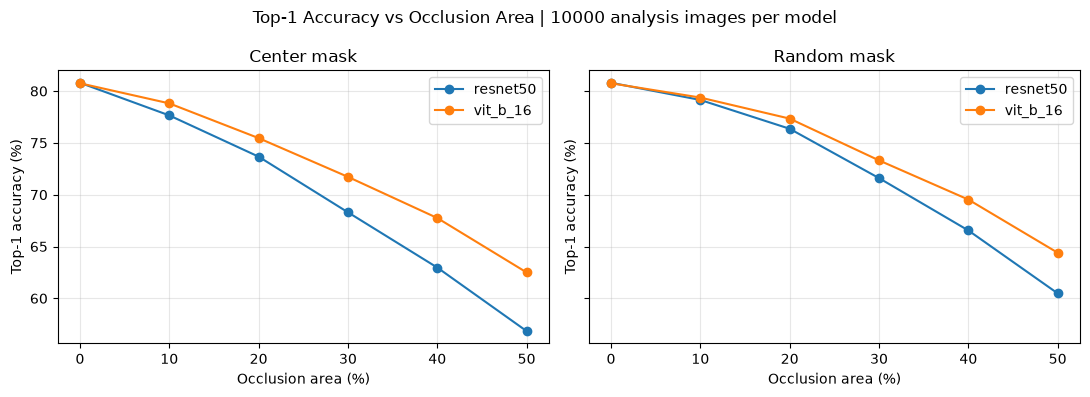

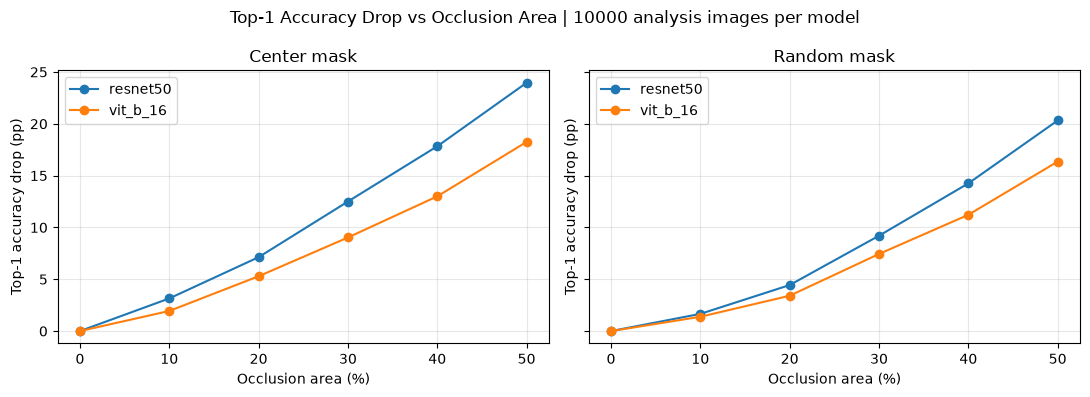

In [7]:
colors = {"resnet50": "tab:blue", "vit_b_16": "tab:orange"}
for field, ylabel, title, filename in [
    ("top1_accuracy", "Top-1 accuracy (%)", "Top-1 Accuracy vs Occlusion Area", "accuracy_vs_occlusion.png"),
    ("absolute_drop_pp", "Top-1 accuracy drop (pp)", "Top-1 Accuracy Drop vs Occlusion Area", "accuracy_drop_vs_occlusion.png"),
]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, position in zip(axes, POSITIONS):
        for name in MODEL_NAMES:
            values = metrics[(metrics["model_name"] == name) & (metrics["position"] == position)].sort_values("severity")
            ax.plot(values["severity"], values[field], marker="o", label=name, color=colors[name])
        ax.set(title=position.capitalize() + " mask", xlabel="Occlusion area (%)", ylabel=ylabel)
        ax.set_xticks(SEVERITIES)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(f"{title} | {N_IMAGES} analysis images per model")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
print("Figures:", FIGURES_DIR.relative_to(ROOT))

## 9. Discussion
Use the executed tables and curves to discuss:

- Which model loses more accuracy as occlusion increases? Does this differ
  between center and random masks?
- How do absolute and relative drops change the comparison when clean subset
  accuracy differs between the models?
- Can prediction consistency remain high while accuracy is low? A repeated
  incorrect prediction is consistent but not correct.
- Center masks may hide the object more often in center-biased images. Paired
  model-input coordinates cover different original views because resize differs.
- One random mask per image/severity is used. Positions at successive severities
  are independent, not nested. Non-monotonic curves are possible; repeated seeds
  would be a separate extension, not part of this pilot.
- The first 100 manifest images are for pilot validation, not a class-balanced
  100-image benchmark. Do not generalize these results or infer causal claims
  about CNN/ViT architectures from two pretrained models alone.

**Official run:** review the pilot, change only `N_IMAGES = 10000`, and restart
and run all cells. A new full-run folder will be created. Keep batch size 16 or
reduce it if GPU memory is limited. This notebook never automatically starts a
10,000-image run, commits files, or pushes to GitHub.

### Pilot validation note (100 images, seed 42)
Clean Top-1 predictions and Top-5 class sets match the saved full-baseline CSVs
for all 100 selected IDs in both models. One ResNet image
(`ILSVRC2012_val_00000128_n01614925.JPEG`) swaps ranks 4 and 5 relative to that CSV;
Top-1 and Top-5 accuracy are unchanged. The exact cause of the ordering difference
was not established. All 24 metric rows were independently recounted from saved
predictions, including ID joins, consistency and both accuracy-drop formulas.
Original baseline files and shared modules remain unchanged.

### Full-run results (10,000 images, seed 42)
Run: `full10000_20261105T051900440637Z`. All 10,000 manifest IDs were evaluated,
with 10 images per class across 1,000 classes. There are 110,000 prediction rows
per model, 24 summary metric rows and 120,000 mask-coordinate rows.

| Model | Clean Top-1 | Clean Top-5 | Center 50% Top-1 | Random 50% Top-1 |
| --- | ---: | ---: | ---: | ---: |
| ResNet-50 | 80.80% | 95.40% | 56.84% | 60.48% |
| ViT-B/16 | 80.75% | 95.31% | 62.50% | 64.40% |

At 50% occlusion, Top-1 drops are 23.96 pp / 20.32 pp for ResNet (center/random)
and 18.25 pp / 16.35 pp for ViT. Under this protocol, ViT loses less accuracy at
these two settings. No bootstrap confidence intervals or extra random seeds
have been run, so these are point estimates for the selected images and masks.

All 24 metric rows were independently recalculated from saved predictions.
All mask coordinates were regenerated and matched; cohort and manifest hashes
were checked. The saved full-baseline predictions restricted to this cohort give
ResNet clean Top-1 80.82%, versus 80.80% in this run: two IDs change Top-1 class
(`ILSVRC2012_val_00034713_n04552348.JPEG` and
`ILSVRC2012_val_00030315_n03259280.JPEG`). Seventeen ResNet Top-5 class sets differ,
but no Top-5 correctness flags change. ViT clean Top-1 and Top-5 sets match on
all 10,000 IDs. The exact cause of the ResNet prediction differences has not been
established. All reported drops use this run's own clean predictions, never the
old baseline accuracy. Original baseline files and shared modules were preserved.
